# Validación de Estaciones con Problemas de Imputación

Este notebook detecta problemas en las series temporales imputadas usando 3 filtros hidrológicos:

1. **Velocidad de Cambio**: Detecta cambios diarios anómalos comparados con histórico
2. **Coherencia Espacial**: Valida correlación con estaciones vecinas
3. **Continuidad de Fronteras**: Detecta saltos bruscos en límites de gaps

**Estaciones a validar:**
- COYONGAL
- RIO_NUEVO
- LAS_PALOMAS
- ARMENIA
- GAMARRA_AUT

---

## PASO 1: Ejecutar Validación

In [1]:
# Importar el validador
import sys
sys.path.append('./funciones')

from validate_imputation import ImputationValidator, generate_validation_report, STATION_NEIGHBORS

# Crear instancia del validador
validator = ImputationValidator(data_path='./datos/processed/')

print("✓ Validador inicializado")

Cargando datos desde: ./datos/processed/Datos_Imputados_v3.csv
✓ Datos cargados: 326,480 registros totales
✓ Estaciones disponibles: 18
✓ Validador inicializado


In [2]:
# Estaciones problemáticas identificadas
problem_stations = ['COYONGAL', 'RIO_NUEVO', 'LAS_PALOMAS', 'ARMENIA', 'GAMARRA_AUT']

# Ejecutar validación para cada estación
results = []

for station in problem_stations:
    # Obtener vecinas para validación espacial
    neighbors = STATION_NEIGHBORS.get(station, [])
    
    # Ejecutar validación completa
    result = validator.validate_station(station, neighbor_stations=neighbors)
    results.append(result)

print("\n" + "="*60)
print("VALIDACIÓN COMPLETADA PARA TODAS LAS ESTACIONES")
print("="*60)


VALIDANDO ESTACION: COYONGAL

Estadisticas base:
  - Registros: 18,628 / 18,628
  - Periodo: 1975-2025
  - Rango: 12.74 - 20.80 m
  - Cambio max historico: 2.294 m/dia

[Filtro 1] Validando velocidad de cambio...
  - Flags detectados: 186
    CRITICAL: 31, WARNING: 155

[Filtro 2] Validando coherencia espacial...
  - Flags detectados: 8822

[Filtro 3] Validando continuidad de fronteras...
  - Flags detectados: 0

RESUMEN: ✗ SERIE CRITICA - Requiere revision completa
  Total flags: 9008 (CRITICAL: 31, WARNING: 8977)

VALIDANDO ESTACION: RIO_NUEVO

Estadisticas base:
  - Registros: 18,739 / 18,993
  - Periodo: 1974-2025
  - Rango: 17.78 - 23.85 m
  - Cambio max historico: 2.366 m/dia

[Filtro 1] Validando velocidad de cambio...
  - Flags detectados: 188
    CRITICAL: 20, WARNING: 168

[Filtro 2] Validando coherencia espacial...
  - Flags detectados: 14147

[Filtro 3] Validando continuidad de fronteras...
  - Flags detectados: 0

RESUMEN: ✗ SERIE CRITICA - Requiere revision completa
  To

---

## PASO 2: Revisar Resultados Detallados

In [6]:
# Mostrar resumen de flags por estación
import pandas as pd

summary_data = []
for r in results:
    summary_data.append({
        'Estación': r['station'],
        'Registros': r['statistics']['n_valid'],
        'Flags Total': r['total_flags'],
        'CRITICAL': r['critical_flags'],
        'WARNING': r['warning_flags'],
        'Evaluación': r['assessment']
    })

df_summary = pd.DataFrame(summary_data)
display(df_summary)

,Estación,Registros,Flags Total,CRITICAL,WARNING,Evaluación
0,COYONGAL,18628,9008,31,8977,✗ SERIE CRITICA - Requiere revision completa
1,RIO_NUEVO,18739,14335,20,14315,✗ SERIE CRITICA - Requiere revision completa
2,LAS_PALOMAS,18988,8918,18,8900,✗ SERIE CRITICA - Requiere revision completa
3,ARMENIA,15078,9972,19,9953,✗ SERIE CRITICA - Requiere revision completa
4,GAMARRA_AUT,4418,1426,2,1424,✗ SERIE CRITICA - Requiere revision completa


---

## PASO 3: Ver Periodos Problemáticos por Estación

In [ ]:
# Seleccionar una estación para ver detalle
ESTACION_A_REVISAR = 'COYONGAL'  # Cambiar por la estación que quieras revisar

# Buscar resultado de esa estación
result = next((r for r in results if r['station'] == ESTACION_A_REVISAR), None)

if result and len(result['problem_periods']) > 0:
    print(f"\nPeriodos problemáticos para {ESTACION_A_REVISAR}:")
    print("="*80)
    display(result['problem_periods'])
else:
    print(f"\n✓ No se detectaron periodos problemáticos para {ESTACION_A_REVISAR}")

In [ ]:
# Ver flags individuales de un periodo específico
if result and len(result['all_flags']) > 0:
    print(f"\nTodos los flags para {ESTACION_A_REVISAR}:")
    print("="*80)
    
    # Mostrar primeros 20 flags
    flags_display = result['all_flags'][['date', 'flag_type', 'severity', 'description']].head(20)
    display(flags_display)

---

## PASO 4: Generar Reporte Completo en Markdown

In [5]:
# Generar reporte en Markdown
report_file = generate_validation_report(results, output_path='./resultados/')

print(f"\n✓ Reporte generado: {report_file}")


✓ Reporte guardado en: ./resultados/validacion_imputacion_problemas.md

✓ Reporte generado: ./resultados/validacion_imputacion_problemas.md


---

## PASO 5: Visualización de Problemas (Opcional)

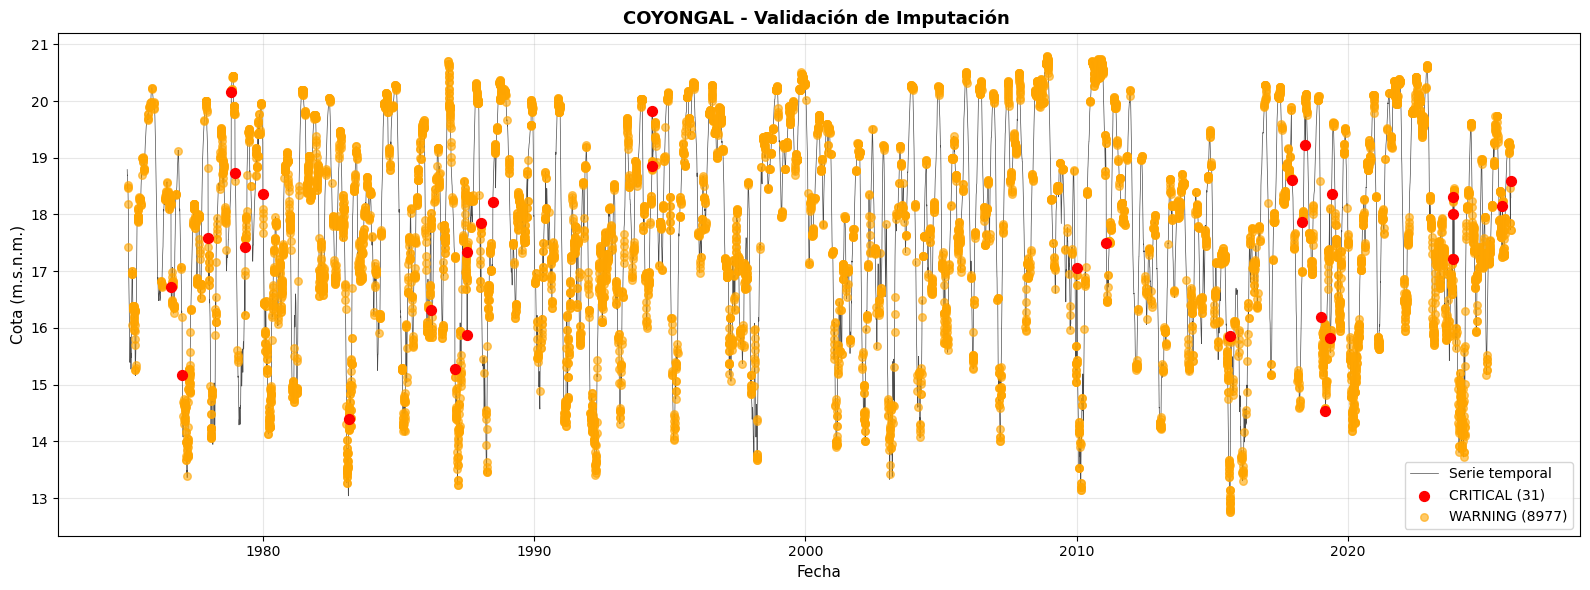

✓ Gráfico guardado: ./resultados/Validacion_COYONGAL.png


In [7]:
# Visualizar serie temporal con flags marcados
import matplotlib.pyplot as plt

def plot_station_with_flags(result, title_suffix=""):
    """Grafica la serie temporal marcando los flags detectados."""
    
    station = result['station']
    df_station = validator.df[validator.df['station'] == station].copy()
    df_station = df_station.sort_values('date')
    
    fig, ax = plt.subplots(figsize=(16, 6))
    
    # Serie completa
    ax.plot(df_station['date'], df_station['level'], color='black', 
            linewidth=0.5, alpha=0.7, label='Serie temporal')
    
    # Marcar flags
    flags = result['all_flags']
    
    if len(flags) > 0:
        # Separar por tipo y severidad
        critical = flags[flags['severity'] == 'CRITICAL']
        warning = flags[flags['severity'] == 'WARNING']
        
        if len(critical) > 0:
            ax.scatter(critical['date'], critical['level'], 
                      color='red', s=50, zorder=5, label=f'CRITICAL ({len(critical)})')
        
        if len(warning) > 0:
            ax.scatter(warning['date'], warning['level'], 
                      color='orange', s=30, alpha=0.6, zorder=4, label=f'WARNING ({len(warning)})')
    
    ax.set_xlabel('Fecha', fontsize=11)
    ax.set_ylabel('Cota (m.s.n.m.)', fontsize=11)
    ax.set_title(f'{station} - Validación de Imputación {title_suffix}', fontsize=13, fontweight='bold')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f'./resultados/Validacion_{station}.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Gráfico guardado: ./resultados/Validacion_{station}.png")

# Generar visualización para una estación
plot_station_with_flags(result)

---

## PASO 6: Exportar Datos de Problemas a CSV

In [ ]:
# Exportar todos los flags a CSV para análisis externo
all_flags_combined = pd.concat([r['all_flags'] for r in results if len(r['all_flags']) > 0], 
                               ignore_index=True)

if len(all_flags_combined) > 0:
    csv_file = './resultados/flags_problemas_todas_estaciones.csv'
    all_flags_combined.to_csv(csv_file, index=False)
    print(f"✓ CSV exportado: {csv_file}")
    print(f"  Total flags: {len(all_flags_combined)}")
else:
    print("✓ No hay flags para exportar")

# Exportar periodos problemáticos
all_periods = []
for r in results:
    if len(r['problem_periods']) > 0:
        df_periods = r['problem_periods'].copy()
        df_periods['station'] = r['station']
        all_periods.append(df_periods)

if all_periods:
    df_all_periods = pd.concat(all_periods, ignore_index=True)
    csv_periods = './resultados/periodos_problematicos.csv'
    df_all_periods.to_csv(csv_periods, index=False)
    print(f"✓ CSV exportado: {csv_periods}")
    display(df_all_periods.head(10))
else:
    print("✓ No hay periodos problemáticos para exportar")

---

## Notas y Próximos Pasos

### Interpretación de Resultados:

- **CRITICAL**: Cambios o saltos que exceden ampliamente los umbrales hidrológicos. Requieren revisión inmediata.
- **WARNING**: Anomalías menores que podrían ser válidas pero merecen verificación.

### Acciones Sugeridas:

1. Revisar manualmente los periodos marcados como CRITICAL
2. Comparar con fotos/aforos de campo si están disponibles
3. Verificar los datos originales (sin imputar) en esas fechas
4. Ajustar los modelos H-H si se detectan problemas sistemáticos
5. Documentar los cambios en la metodología de imputación

### Archivos Generados:

- `./resultados/validacion_imputacion_problemas.md` - Reporte completo
- `./resultados/Validacion_{ESTACION}.png` - Gráficos con flags marcados
- `./resultados/flags_problemas_todas_estaciones.csv` - Todos los flags
- `./resultados/periodos_problematicos.csv` - Periodos resumidos